# Crank-Nicolson Black-Scholes Solver

In this notebook, I test my Crank-Nicolson solver for the Black-Scholes PDE and give some exposition on the mathematical formulation behind it.

I assume that the underlying stock price follows Geometric Brownian Motion under the risk-neutral measure. This leads to the Black-Scholes PDE for a European call option. I then use the transformation

$$\tau = T - t,$$

where $\tau$ denotes time to maturity.

The terminal condition is

$$V(S,T) = \max(S-K,0),$$

which becomes the initial condition in time-to-maturity form:

$$V(S,0) = \max(S-K,0).$$

The boundary conditions used are

$$V(0,\tau)=0,$$

and

$$V(S_{\max},\tau)=S_{\max}-Ke^{-r\tau}.$$

I take $S_{\max}=3K$, which is sufficiently large that the upper boundary approximates the asymptotic behaviour of a European call option.

## Transforming the Black-Scholes Equation

The Black-Scholes PDE is

$$
\frac{\partial V}{\partial t}
+ \frac{1}{2}\sigma^2 S^2 \frac{\partial^2 V}{\partial S^2}
+ rS \frac{\partial V}{\partial S}
- rV = 0.
$$

Using the time-to-maturity variable $\tau = T-t$, this becomes

$$
\frac{\partial V}{\partial \tau}
=
\frac{1}{2}\sigma^2 S^2 \frac{\partial^2 V}{\partial S^2}
+ rS \frac{\partial V}{\partial S}
- rV.
$$

The derivation of this transformation is included in the report.

## Spatial Discretisation

The spatial domain $[0,S_{\max}]$ is divided into $M$ uniform intervals, giving $M+1$ grid points. The spatial step size is

$$
\Delta S = \frac{S_{\max}}{M}.
$$

The numerical solution at stock price $S_i$ and time-to-maturity $\tau_j$ is denoted by

$$
U_i^j \approx V(S_i,\tau_j).
$$

The first and second spatial derivatives are approximated using second-order central finite difference schemes:

$$
\frac{\partial V}{\partial S}\biggr|_{S_i}
\approx
\frac{U_{i+1}^j - U_{i-1}^j}{2\Delta S},
$$

and

$$
\frac{\partial^2 V}{\partial S^2}\biggr|_{S_i}
\approx
\frac{U_{i+1}^j - 2U_i^j + U_{i-1}^j}{(\Delta S)^2}.
$$

## Crank-Nicolson Temporal Discretisation

The time-to-maturity interval $[0,T]$ is divided into $N$ uniform time steps, with

$$
\Delta \tau = \frac{T}{N}.
$$

Define the Black-Scholes spatial differential operator

$$
L(V)
=
\frac{1}{2}\sigma^2 S^2 \frac{\partial^2 V}{\partial S^2}
+ rS\frac{\partial V}{\partial S}
- rV.
$$

The Crank-Nicolson method averages this operator between two consecutive time levels:

$$
\frac{U_i^{j+1} - U_i^j}{\Delta \tau}
=
\frac{1}{2}
\left[
L(U_i^{j+1}) + L(U_i^j)
\right].
$$

This results in a tridiagonal linear system at each time step:

$$
A U^{j+1} = B U^j + b^j,
$$

where $A$ and $B$ are tridiagonal matrices determined by the model parameters and grid sizes, while $b^j$ contains the contributions from the boundary conditions.

In [5]:
import sys
sys.path.append("..")

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.crank_nicolson import Crank_Nicolson_Solver
from src.analytical import call_price, black_scholes_call_grid
from src.metrics import error_summary

In [6]:
# Model parameters.

K = 100
T = 1.0
r = 0.05
sigma = 0.2
S0 = 100
S_max = 3 * K

In [ ]:
# Solving using the Crank-Nicolson method.

M = 100
N = 100

bs_price = float(call_price(S0=S0,tau=T,K=K,r=r,sigma=sigma))

print(f"Analytical price:      {bs_price:.6f}")
print(f"Crank-Nicolson price:  {price:.6f}")
print(f"Absolute error:        {abs(price - bs_price):.6e}")

Analytical price:      10.450584
Crank-Nicolson price:  10.452085
Absolute error:        1.501885e-03


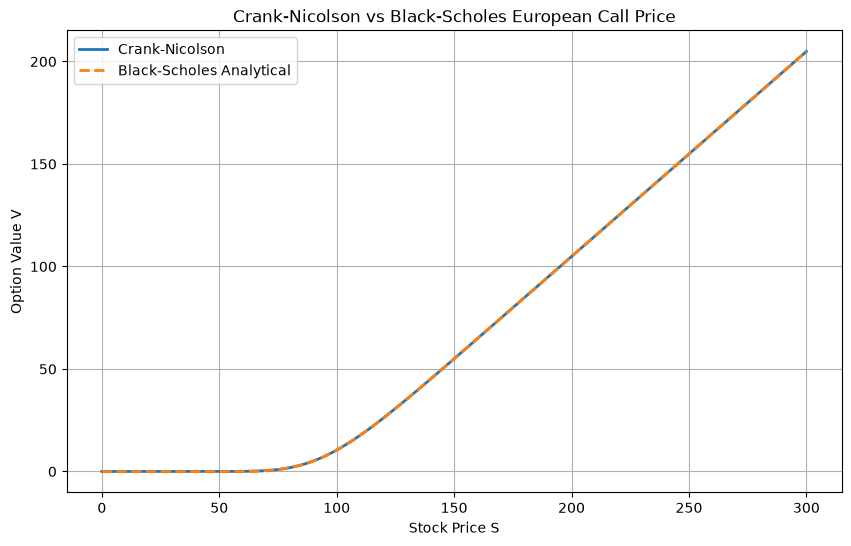

In [ ]:
bs_values = np.zeros_like(S, dtype=float)

positive_S = S > 0
bs_values = call_price(S0=S,tau=T,K=K,r=r,sigma=sigma)

abs_error = np.abs(V - bs_values)

plt.figure(figsize=(10, 6))
plt.plot(S, V, label="Crank-Nicolson", linewidth=2)
plt.plot(S, bs_values, "--", label="Black-Scholes Analytical", linewidth=2)

plt.xlabel("Stock Price S")
plt.ylabel("Option Value V")
plt.title("Crank-Nicolson vs Black-Scholes European Call Price")
plt.grid()
plt.legend()
plt.show()

The absolute error between my Crank-Nicolson solver and the analytical price from the solution of the Black-Scholes equation is small, indicating that it approximates the call prices well. I will now create some error and convergence plots.

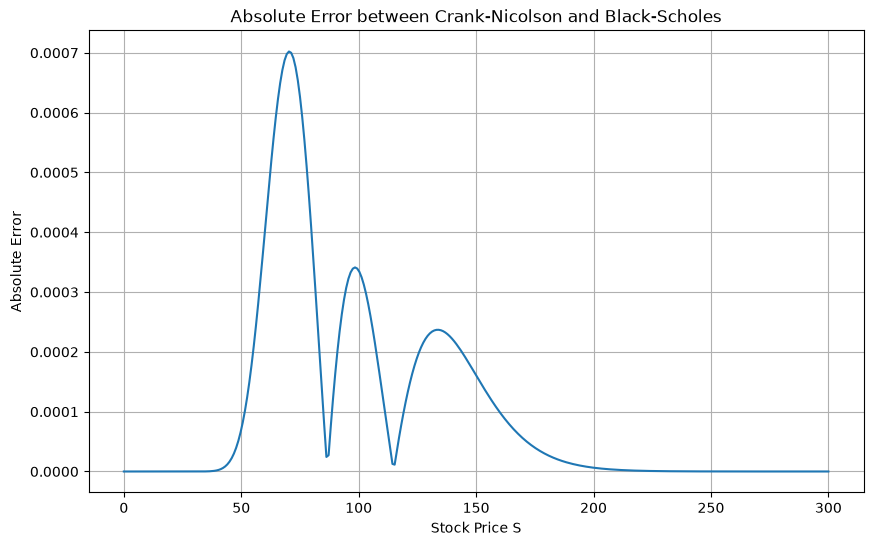

In [11]:
abs_error = np.abs(V - bs_values)

plt.figure(figsize=(10, 6))
plt.plot(S, abs_error)

plt.xlabel("Stock Price S")
plt.ylabel("Absolute Error")
plt.title("Absolute Error between Crank-Nicolson and Black-Scholes")
plt.grid()
plt.show()

In [12]:
# I will now compute some 1-D error metrics.

one_dimensional_metrics = error_summary(V, bs_values)

one_dimensional_metrics_table = pd.DataFrame({
    "Metric": one_dimensional_metrics.keys(),
    "Value": one_dimensional_metrics.values()
})

one_dimensional_metrics_table

,Metric,Value
0,MSE,3.735534e-08
1,RMSE,1.932753e-04
2,MAE,1.023117e-04
3,Max Abs Error,7.021647e-04
4,Relative L2 Error,1.972350e-06


In [ ]:
# I will vary the grid size and examine how the error changes as the grid gets finer. 

grid_sizes = [10, 20, 40, 80, 160, 320]

results = []

for grid_size in grid_sizes:
    M = N = grid_size

    solver = Crank_Nicolson_Solver(S0=S0,K=K,T=T,r=r,sigma=sigma,S_max=S_max,M=M,N=N)

    price, S, V = solver.solve()

    bs_values = np.zeros_like(S, dtype=float)
    positive_S = S > 0

    bs_values = call_price(S0=S,tau=T,K=K,r=r,sigma=sigma)

    abs_error = np.abs(V - bs_values)

    abs_error = np.abs(V - bs_values)

    max_error = np.max(abs_error)
    rmse_error = np.sqrt(np.mean(abs_error ** 2))
    mae_error = np.mean(abs_error)
    relative_l2 = np.linalg.norm(V - bs_values) / np.linalg.norm(bs_values)

    dS = S_max / M
    dt = T / N

    results.append({
        "M": M,
        "N": N,
        "dS": dS,
        "dt": dt,
        "Max Abs Error": max_error,
        "RMSE": rmse_error,
        "MAE": mae_error,
        "Relative L2 Error": relative_l2
    })

results_df = pd.DataFrame(results)

results_df

,M,N,dS,dt,Max Abs Error,RMSE,MAE,Relative L2 Error
0,10,10,30.0000,0.100000,0.337321,0.142145,0.084752,0.001374
1,20,20,15.0000,0.050000,0.185788,0.050087,0.023141,0.000498
2,40,40,7.5000,0.025000,0.039842,0.011984,0.006531,0.000121
3,80,80,3.7500,0.012500,0.011445,0.003107,0.001619,0.000032
4,160,160,1.8750,0.006250,0.002739,0.000765,0.000409,0.000008
5,320,320,0.9375,0.003125,0.000702,0.000193,0.000102,0.000002


In [ ]:
# For better readability, I will format the results table to display the errors in scientific notation and the grid sizes in fixed-point notation.

results_df.style.format({
    "dS": "{:.6f}",
    "dt": "{:.6f}",
    "Max Abs Error": "{:.6e}",
    "RMSE": "{:.6e}",
    "MAE": "{:.6e}",
    "Relative L2 Error": "{:.6e}"
})



,M,N,dS,dt,Max Abs Error,RMSE,MAE,Relative L2 Error
0,10,10,30.000000,0.100000,3.373212e-01,1.421454e-01,8.475183e-02,1.374287e-03
1,20,20,15.000000,0.050000,1.857879e-01,5.008696e-02,2.314092e-02,4.975212e-04
2,40,40,7.500000,0.025000,3.984250e-02,1.198356e-02,6.531193e-03,1.207347e-04
3,80,80,3.750000,0.012500,1.144514e-02,3.107325e-03,1.619420e-03,3.153482e-05
4,160,160,1.875000,0.006250,2.739162e-03,7.651965e-04,4.086503e-04,7.794277e-06
5,320,320,0.937500,0.003125,7.021647e-04,1.932753e-04,1.023117e-04,1.972350e-06


As the grid is refined clearly this Crank-Nicolson method converges. Both RMSE and Max Absolute Error both converge approximately in line with the second order convergence reference slope. 

In [17]:
# I will compute the convergence rates based on the errors and grid sizes.

results_df["RMSE Rate"] = np.nan
results_df["Max Abs Error Rate"] = np.nan

for i in range(1, len(results_df)):
    results_df.loc[i, "RMSE Rate"] = (
        np.log(results_df.loc[i - 1, "RMSE"] / results_df.loc[i, "RMSE"])
        / np.log(results_df.loc[i - 1, "dS"] / results_df.loc[i, "dS"])
    )

    results_df.loc[i, "Max Abs Error Rate"] = (
        np.log(results_df.loc[i - 1, "Max Abs Error"] / results_df.loc[i, "Max Abs Error"])
        / np.log(results_df.loc[i - 1, "dS"] / results_df.loc[i, "dS"])
    )

results_df

,M,N,dS,dt,Max Abs Error,RMSE,MAE,Relative L2 Error,RMSE Rate,Max Abs Error Rate
0,10,10,30.0000,0.100000,0.337321,0.142145,0.084752,0.001374,NaN,NaN
1,20,20,15.0000,0.050000,0.185788,0.050087,0.023141,0.000498,1.504860,0.860466
2,40,40,7.5000,0.025000,0.039842,0.011984,0.006531,0.000121,2.063378,2.221276
3,80,80,3.7500,0.012500,0.011445,0.003107,0.001619,0.000032,1.947312,1.799573
4,160,160,1.8750,0.006250,0.002739,0.000765,0.000409,0.000008,2.021771,2.062929
5,320,320,0.9375,0.003125,0.000702,0.000193,0.000102,0.000002,1.985173,1.963853


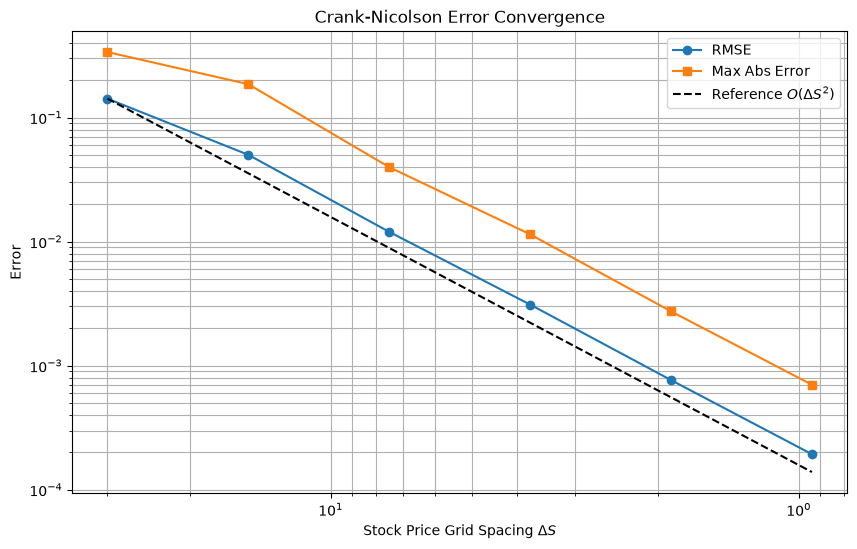

In [18]:
# Generating a convergence plot.

plt.figure(figsize=(10, 6))

plt.loglog(
    results_df["dS"],
    results_df["RMSE"],
    marker="o",
    label="RMSE"
)

plt.loglog(
    results_df["dS"],
    results_df["Max Abs Error"],
    marker="s",
    label="Max Abs Error"
)

reference = results_df["RMSE"].iloc[0] * (
    results_df["dS"] / results_df["dS"].iloc[0]
) ** 2

plt.loglog(
    results_df["dS"],
    reference,
    linestyle="--",
    color="black",
    label=r"Reference $O(\Delta S^2)$"
)

plt.xlabel(r"Stock Price Grid Spacing $\Delta S$")
plt.ylabel("Error")
plt.title("Crank-Nicolson Error Convergence")
plt.grid(which="both")
plt.legend()
plt.gca().invert_xaxis()
plt.show()

I will now do a full surface evaluation so that I can more easily compare this method with the PINN and PIKAN architectures.

In [26]:
S_eval = np.linspace(0, S_max, 100)
tau_eval = np.linspace(0, T, 50)

S_grid_np, tau_grid_np = np.meshgrid(S_eval, tau_eval, indexing="ij")

evaluation_grid = f"{len(S_eval)} x {len(tau_eval)}"

V_exact_surface = black_scholes_call_grid(
    S0=S_grid_np,
    tau=tau_grid_np,
    K=K,
    r=r,
    sigma=sigma
)

In [27]:
# Defining a function that evaluates the Crank-Nicolson method over a surface.

def evaluate_crank_nicolson_surface(S_eval, tau_eval, K, r, sigma, S_max, M=320, N=320):
    V_cn_surface = np.zeros((len(S_eval), len(tau_eval)))

    for j, tau in enumerate(tau_eval):
        if tau <= 1e-12:
            V_cn_surface[:, j] = np.maximum(S_eval - K, 0.0)
            continue

        solver = Crank_Nicolson_Solver(
            S0=100,
            K=K,
            T=float(tau),
            r=r,
            sigma=sigma,
            S_max=S_max,
            M=M,
            N=N
        )

        _, S_cn, V_cn = solver.solve()

        V_cn_surface[:, j] = np.interp(S_eval, S_cn, V_cn)

    return V_cn_surface

In [32]:
M_cn = 100
N_cn = 100

start_time = time.perf_counter()

V_cn_surface = evaluate_crank_nicolson_surface(
    S_eval=S_eval,
    tau_eval=tau_eval,
    K=K,
    r=r,
    sigma=sigma,
    S_max=S_max,
    M=M_cn,
    N=N_cn
)

cn_runtime = time.perf_counter() - start_time

cn_metrics = error_summary(V_cn_surface, V_exact_surface)

cn_metrics_table = pd.DataFrame({
    "Metric": cn_metrics.keys(),
    "Value": cn_metrics.values()
})

print(f"Crank-Nicolson surface runtime: {cn_runtime:.4f} seconds")

cn_metrics_table

Crank-Nicolson surface runtime: 0.5141 seconds


,Metric,Value
0,MSE,0.000096
1,RMSE,0.009815
2,MAE,0.003887
3,Max Abs Error,0.129387
4,Relative L2 Error,0.000102


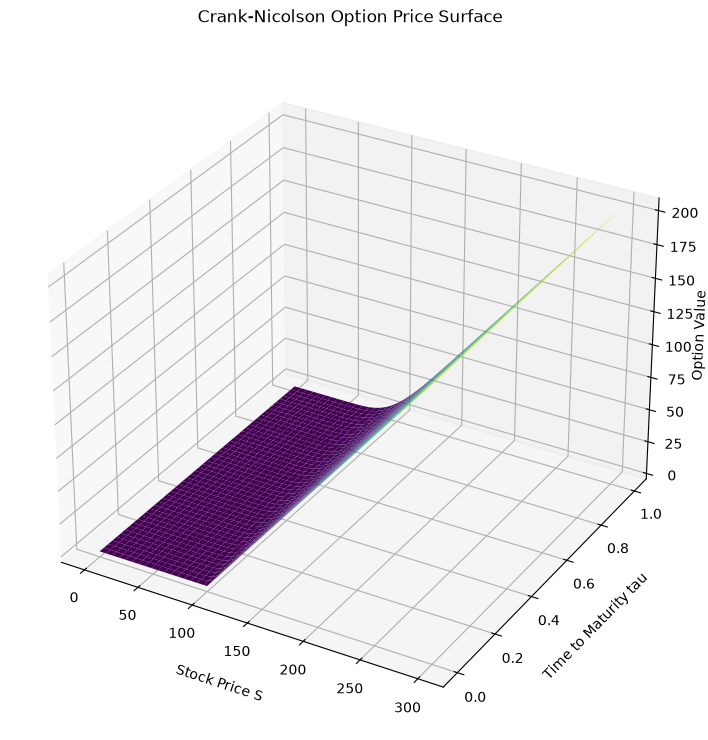

In [33]:
# Crank-Nicolson price surface

fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection="3d")

ax.plot_surface(S_grid_np, tau_grid_np, V_cn_surface, cmap="viridis")

ax.set_title("Crank-Nicolson Option Price Surface", pad=20)
ax.set_xlabel("Stock Price S", labelpad=10)
ax.set_ylabel("Time to Maturity tau", labelpad=10)
ax.set_zlabel("Option Value", labelpad=0)

fig.subplots_adjust(left=0.02, right=0.78, top=0.9, bottom=0.05)

plt.show()

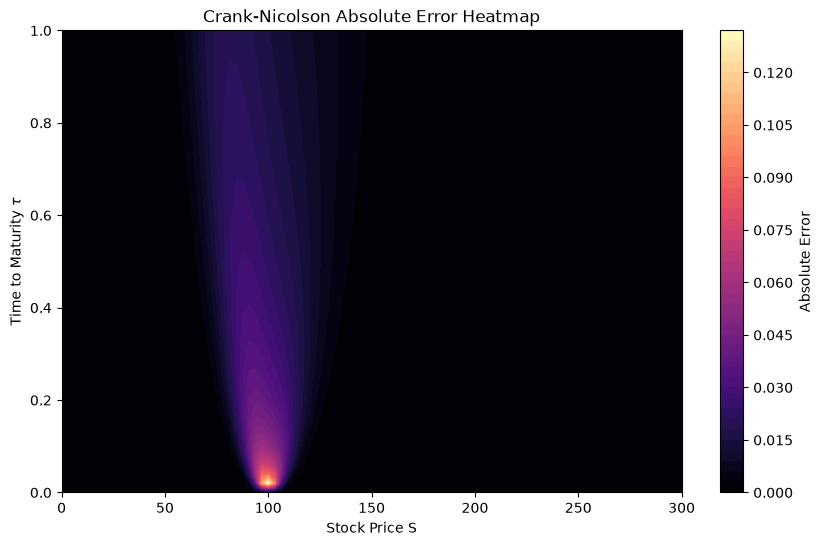

In [34]:
# Absolute error heatmap

abs_error_surface_cn = np.abs(V_cn_surface - V_exact_surface)

plt.figure(figsize=(10, 6))

plt.contourf(S_grid_np, tau_grid_np, abs_error_surface_cn, levels=50, cmap="magma")
plt.colorbar(label="Absolute Error")

plt.title("Crank-Nicolson Absolute Error Heatmap")
plt.xlabel("Stock Price S")
plt.ylabel(r"Time to Maturity $\tau$")

plt.show()

In [35]:
# This is designed to be the same format as the comparisons in comparison.ipynb

cn_comparison_row = {
    "Method": "Crank-Nicolson",
    "Architecture / Grid": f"M={M_cn}, N={N_cn}",
    "Trainable Parameters": 0,
    "Epochs": "N/A",
    "Training Points": "N/A",
    "Evaluation Grid": evaluation_grid,
    "Runtime (s)": cn_runtime,
    "Runtime per Epoch (s)": "N/A",
    "MSE": cn_metrics["MSE"],
    "RMSE": cn_metrics["RMSE"],
    "MAE": cn_metrics["MAE"],
    "Max Abs Error": cn_metrics["Max Abs Error"],
    "Relative L2 Error": cn_metrics["Relative L2 Error"],
}

cn_comparison_table = pd.DataFrame([cn_comparison_row])

cn_comparison_table

,Method,Architecture / Grid,Trainable Parameters,Epochs,Training Points,Evaluation Grid,Runtime (s),Runtime per Epoch (s),MSE,RMSE,MAE,Max Abs Error,Relative L2 Error
0,Crank-Nicolson,"M=100, N=100",0,N/A,N/A,100 x 50,0.5141,N/A,0.000096,0.009815,0.003887,0.129387,0.000102
